In [1]:
import pandas as pd
import numpy as np
import pickle
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
import matplotlib.pyplot as plt
import seaborn as sns
# set random seed for reproducibility
np.random.seed(42)
print("all libraries imported successfully!")

all libraries imported successfully!


3.data loading 
we will use the california housing dataset,which is a classic dataset for regression task.it cntains information about houses in california and their median house values.

In [2]:
# load the california Housing datasets

housing=fetch_california_housing(as_frame=True)
X=housing.data
y=housing.target
print("Dataset loaded successfully")
print(f"Features (X) shape:{X.shape}")
print(f"target (y) shape:{y.shape}")
print(f"\ndataset description")
print(housing.DESCR[:500]+"...")


Dataset loaded successfully
Features (X) shape:(20640, 8)
target (y) shape:(20640,)

dataset description
.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group popu...


In [3]:
# Display basic information about the dataset
print("features names")
print(X.columns.tolist())
print("\nfirst 5 row of features(x):")
print(X.head())
print("\nfirst 5 row of target (x):")
print(y.head())
print("\nbasic statistics")
print(X.describe())

features names
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

first 5 row of features(x):
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

first 5 row of target (x):
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

basic statistics
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.8706

4.data exploration and visualization
<!-- let's explore our data to better understand the relatioshps between features and the target variables  -->

In [4]:
# check for mmissing values
print("missing values in  the features:")
print(X.isnull().sum())
print(f"\nmissing values in target: {y.isnull().sum()}")
# basic statistics
print("\ntarget variable statistics:")
print(f"Mean house value: ${y.mean():.2f} (in hundreds of thousands)")
print(f"Median house value: ${y.median():.2f} (in hundreds of thousands)")
print(f"Min house value: ${y.min():.2f} (in hundreds of thousands)")
print(f"Max house value: ${y.max():.2f} (in hundreds of thousands)")



missing values in  the features:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

missing values in target: 0

target variable statistics:
Mean house value: $2.07 (in hundreds of thousands)
Median house value: $1.80 (in hundreds of thousands)
Min house value: $0.15 (in hundreds of thousands)
Max house value: $5.00 (in hundreds of thousands)


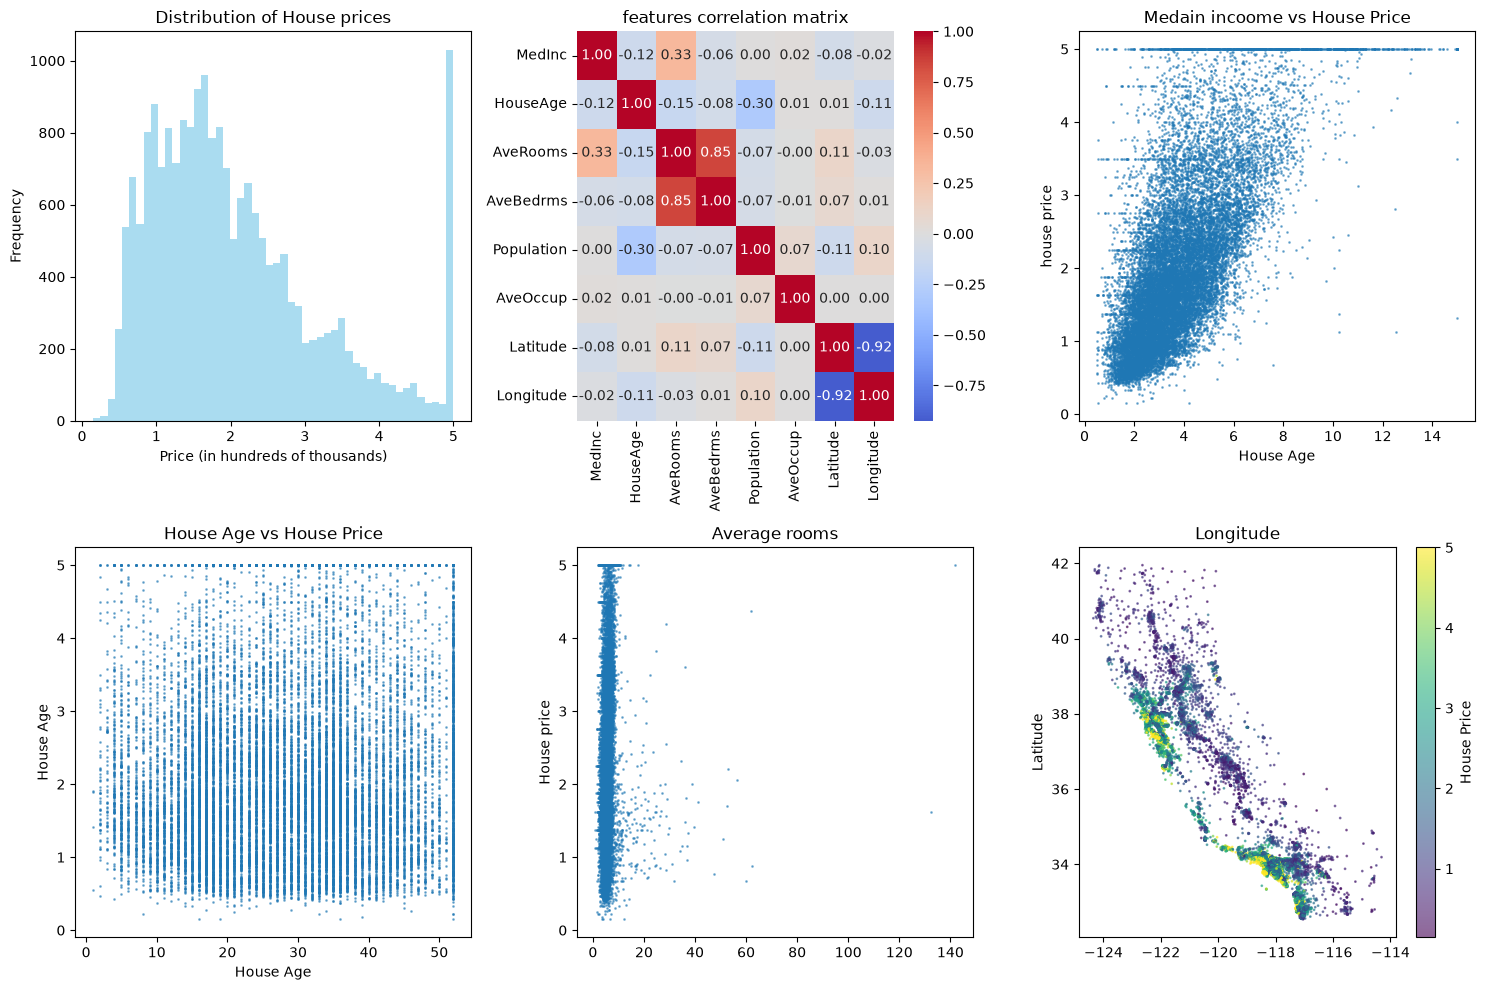

In [5]:
# create visualization
plt.figure(figsize=(15,10))
# distribution of target varable
plt.subplot(2,3,1)
plt.hist(y,bins=50,alpha=0.7,color='skyblue')
plt.title("Distribution of House prices")
plt.xlabel('Price (in hundreds of thousands)')
plt.ylabel('Frequency')
# corelation heatmap
plt.subplot(2,3,2)
correlation_matrix=X.corr()
sns.heatmap(correlation_matrix, annot=True,cmap='coolwarm',center=0,fmt='.2f')
plt.title('features correlation matrix')
# scatter plot:medInc Price
plt.subplot(2,3,3)
plt.scatter(X['MedInc'],y,alpha=0.5,s=1)
plt.title("Medain incoome vs House Price")
plt.xlabel("House Age")
plt.ylabel("house price")
# Scatter plot:HouseAge vs price
plt.subplot(2,3,4)
plt.scatter(X['HouseAge'],y,alpha=0.5,s=1)
plt.title("House Age vs House Price")
plt.xlabel("House Age")

plt.ylabel("House Age")
# scatter plot :Averooms vs Price
plt.subplot(2,3,5)
plt.scatter(X['AveRooms'],y,alpha=0.5,s=1)
plt.title("Average rooms vs House Price")
plt.title("Average rooms")
plt.ylabel("House price")
# Geographic plot
plt.subplot(2,3,6)
plt.scatter(X['Longitude'],X['Latitude'],c=y,cmap='viridis',alpha=0.6,s=1)
plt.colorbar(label='House Price')
plt.title("Gegraphic Distribution of Huse prices")
plt.title("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

5.data preprocessing and cleaning
in this section we will perform data preprocessing which includes spliting data into training and testing sets(80% training and 20% testing) and scaling the features.

In [28]:
# Splitting data into training and testing sets (80% training and 20% testing)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,shuffle=True)
print("Data split completed")

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print(f"\nTraining set: {len(X_train)} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set: {len(X_test)} samples ({len(X_test)/len(X)*100:.1f}%)")


Data split completed
X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)

Training set: 16512 samples (80.0%)
Test set: 4128 samples (20.0%)


In [27]:
# scale the features using the standardScaler
# this is important for linear regression to ensures all features contribute equally
scaler=StandardScaler()
# fit the scaler on training data and transform both training and test data
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)
print("features scaling completed!")
print("original X_train statistics")
print(f"mean:{X_train.mean().mean():.3f}")
print(f"std:{X_train.std().mean():.3f}")
print("\nScaled X_train statistics")
print(f"mean:{X_train.mean().mean():.3f}")
print(f"std:{X_train.std().mean():.3f}")
print("\nfirst 5 rows of scaled x_train:")
print(X_train_scaled[:5])


features scaling completed!
original X_train statistics
mean:173.079
std:146.263

Scaled X_train statistics
mean:173.079
std:146.263

first 5 rows of scaled x_train:
[[-0.326196    0.34849025 -0.17491646 -0.20836543  0.76827628  0.05137609
  -1.3728112   1.27258656]
 [-0.03584338  1.61811813 -0.40283542 -0.12853018 -0.09890135 -0.11736222
  -0.87669601  0.70916212]
 [ 0.14470145 -1.95271028  0.08821601 -0.25753771 -0.44981806 -0.03227969
  -0.46014647 -0.44760309]
 [-1.01786438  0.58654547 -0.60001532 -0.14515634 -0.00743434  0.07750687
  -1.38217186  1.23269811]
 [-0.17148831  1.14200767  0.3490073   0.08662432 -0.48587717 -0.06883176
   0.5320839  -0.10855122]]


6.Model training 
we will train a linear regression model from scikit-learn .Linear regression model from scikit-learn .linear regresion is a good starting point for regression tasks and provides inrterpretable results.
 

In [26]:
# initilize the linear regression model 
model=LinearRegression()
print("training the linear regression model...")
# train the model
model.fit(X_train_scaled,y_train)
print("model training completed!!!")
print(f"\nmodel cofficients:{model.coef_}")
print(f"\nmodel intercepts:{model.intercept_:.4f}")


training the linear regression model...
model training completed!!!

model cofficients:[ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]

model intercepts:2.0719


7.model evaluation
let's evaluate our trained model on the both training and test set to understand its performance.


In [25]:
# make predictions on both training and test set
y_train_pred=model.predict(X_train_scaled)
y_test_pred=model.predict(X_test_scaled)
# calculate evluation matrics
train_mse=mean_squared_error(y_train,y_train_pred)
test_mse=mean_squared_error(y_test,y_test_pred)
train_r2=r2_score(y_train,y_train_pred)
test_r2=r2_score(y_test,y_test_pred)
print("model evaluation results:")
print("=",40)
print(f"trainong set:")
print(f"mean square error:{train_mse:.4f}")
print(f"root mean square error:{np.sqrt(train_mse):.4f}")
print(f"R² score: {train_r2:.4f}")
print(f"\ntest set:")
print(f"Mean squared error:{test_mse:.4f}")
print(f"root Mean squared error:{np.sqrt(test_mse):.4f}")
print(f"R² score: {test_r2:.4f}")
print(f"\nmodel performance summary:")
print(f"the model explains{test_r2*100:.1f}% of the variance in house prices.")
print(f"Average prediction error:${np.sqrt(test_mse)*100:.0f}k")




model evaluation results:
= 40
trainong set:
mean square error:0.5179
root mean square error:0.7197
R² score: 0.6126

test set:
Mean squared error:0.5389
root Mean squared error:0.7341
R² score: 0.5888

model performance summary:
the model explains58.9% of the variance in house prices.
Average prediction error:$73k


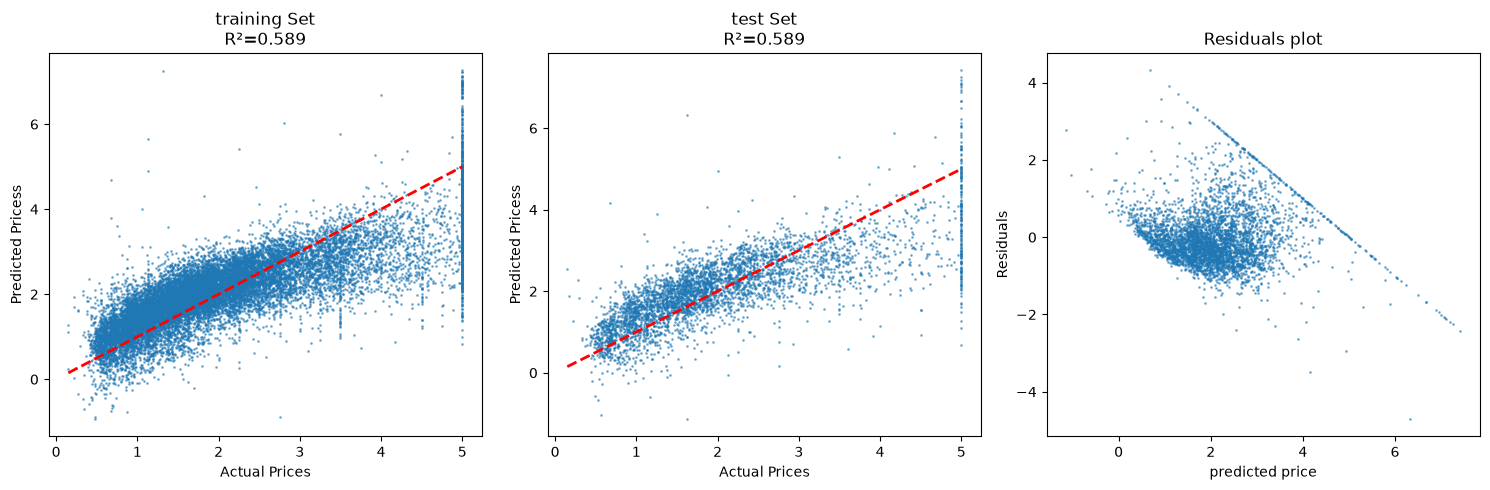

In [23]:
# visualize predictions  vs actual values
plt.figure(figsize=(15,5))
# training set predictions
plt.subplot(1,3,1)
plt.scatter(y_train,y_train_pred,alpha=0.5,s=1)
# plt.plot([y_train.min(),y_train.max()],[y_train.min(),y_train.max()],'r--', 1w=2)

plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    'r--',
    lw=2
)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Pricess")
plt.title(f'training Set\nR²={test_r2:.3f}')
# test set pridctions
plt.subplot(1,3,2)
plt.scatter(y_test,y_test_pred,alpha=0.5,s=1)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2
)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Pricess")
plt.title(f'test Set\nR²={test_r2:.3f}')
# Residuals plot
plt.subplot(1,3,3)
residuals=y_test-y_test_pred
plt.scatter(y_test_pred,residuals,alpha=0.5,s=1)
plt.xlabel('predicted price')
plt.ylabel('Residuals')
plt.title("Residuals plot")
plt.tight_layout()
plt.show()

8.Model saving
now we'll save our train model and scale using pickle.This is crucial for developmentas we need to the next same preprocessing steps during inference.

In [22]:
# save the trained model using pickle
model_filename='linear_regrssion_model.pkl'
with open(model_filename,'wb') as file:
    pickle.dump(model, file)

print(f"trained model save to {model_filename}")    
# save the  scale as well(very importtant for development!)
scale_filename='scaler.pkl'
with open(scale_filename,'wb') as file:
    pickle.dump(scaler,file)

# verify that we can load the model back
print("\nverifying saved file...")
with open(model_filename,'rb')as file:
    loaded_model=pickle.load(file)

print("model and scaler loaded successfully for verification.")
# test the loaded model with the sample prediction
sample_prediction=loaded_model.predict(X_test_scaled[:1])
print(f"Sample prediction with loaded model:${sample_prediction[0]*100:.0f}k")
print(f"Actual value for sample:${y_test.iloc[0]*100:.0f}k")
print(f"Prediction error:${abs(sample_prediction[0]-y_test.iloc[0])*100:.0f}k")



trained model save to linear_regrssion_model.pkl

verifying saved file...
model and scaler loaded successfully for verification.
Sample prediction with loaded model:$70k
Actual value for sample:$48k
Prediction error:$23k


9.Preparing for Development
<!-- Now that we have our trained model for scaler savwed lat's prepare some example data and test our to ensures its ready for development with Fastapi -->

In [21]:
# create example input data for testing the Api
example_house={
"MedInc":0.8,       #median imcome in block group
"HouseAge":28.0,    #median house age in block group
"AvgRooms":5.4,     #Average number of rooms per household
"Avgbedrms":1.0,    #Average number of bedrooms per household
"Population":3000.0,#Block group population
"AveOccup":3.0,     #Average number of households members
"Latitude":34.0,    #Block group Latitude
"longitude":-118.0  #Block group Longitude
}
print("example house features for Api testing:")
for feature,value in example_house.items():
    print(f"{feature}:{value}")

    # test predivtion with our example
example_array=np.array([example_house[col] for col in X.columns]).reshape(1,-1) 
example_scaled=scaler.transform(example_array)
example_prediction=model.predict(example_scaled)[0]
print(f"\nPredicted house price:${example_prediction*100:.0f}k")  
# save example data for APi documentation
import json
with open('example_input.json','w') as f:
    json.dump(example_house, f,index=2)
print("example input saved to 'example_input.json'")   
print("Model is ready for deployment with FastApi") 

example house features for Api testing:
MedInc:0.8
HouseAge:28.0
AvgRooms:5.4
Avgbedrms:1.0
Population:3000.0
AveOccup:3.0
Latitude:34.0
longitude:-118.0


KeyError: 'AveRooms'